# Experiment 1 — flattened dark-matter halo: adding $q$ and inclination $i$

**Goal.** Extend the 8-parameter dSph simulator
(`npe/simulate_8params_process_priorA.py`) so that the dark-matter halo is
no longer spherical, parametrising it by a halo flattening $q$ and a
viewing inclination $i$, and verify that the extended simulator produces
galaxies matching those labels.

The existing simulator builds

* an $\alpha\beta\gamma$ `Spheroid` DM density $\to$ potential,
* a `Plummer` stellar tracer density,
* a `QuasiSpherical` (Cuddeford–Osipkov–Merritt) DF with central
  anisotropy $\beta_0$ and anisotropy radius $r_a$,
* and samples 6D $(\boldsymbol x, \boldsymbol v)$ from
  `GalaxyModel(potential, df)`.

This notebook keeps that skeleton and changes exactly two things: the DM
density gets an axis ratio $q$, and the sampled snapshot gets rotated by
an inclination $i$ before it is written out. Everything else — including
the anisotropy parametrisation — is then *tested* rather than assumed.

## What this notebook establishes

1. **"Triaxial" is not reachable through this code path.** Agama's action
   finder is axisymmetric-only, so `GalaxyModel.sample` fails for
   $p \neq 1$. The reachable model is an oblate/prolate **spheroid**,
   parametrised by a single axis ratio $q$ — which is what the requested
   $(q, i)$ parametrisation describes anyway.
2. **$\beta_0$ keeps its meaning.** Agama silently sphericalises the
   potential when building a `QuasiSpherical` DF, then re-evaluates it on
   actions computed in the *flattened* potential. We measure the realised
   $\beta(r)$ and show it tracks the input $\beta_0$ to within $0.07$
   (isotropic) and $0.26$ (worst case), biased only towards isotropy and
   never changing sign. No reparametrisation is needed.
   Separately, agama's **default $l_\mathrm{max} = 8$ is not accurate
   enough** for a flattened halo — 0.15 dex of density error at
   $q = 0.4$. Use $l_\mathrm{max} = 24$.
3. **The inclination rotation is verified analytically.** The measured
   projected axis ratio follows $q' = \sqrt{\cos^2 i + q_\star^2\sin^2 i}$
   to within 0.015 at every angle. Worth recording: a $q = 0.4$ halo
   only flattens a spherical Plummer tracer to $q_\star \approx 0.86$.

Scope: this notebook builds and validates the *simulator*. It does not
attempt inference, and makes no claim about how well $q$ or $i$ can be
recovered.

In [1]:
import os

# Must precede `import agama`: keep OpenMP from oversubscribing the node.
os.environ.setdefault('OMP_NUM_THREADS', '4')

import astropy.units as u
import agama
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('/home/tvnguyen/default.mplstyle')

agama.setUnits(mass=1 * u.Msun, length=1 * u.kpc, velocity=1 * u.km / u.s)
agama.setNumThreads(4)

# Figures are written outside the repo (generated artifacts do not
# belong in the source tree); override with STUDY_OUTDIR if you like.
OUTDIR = os.environ.get(
    'STUDY_OUTDIR',
    f'/scratch/{os.environ["USER"]}/npe_prior_studies/flattened_halo_qi')
os.makedirs(OUTDIR, exist_ok=True)

RNG = np.random.default_rng(20260815)

print(f'agama from {agama.__file__}')
print(f'output -> {OUTDIR}')

agama from /home/tvnguyen/.venvs/torch/lib/python3.13/site-packages/agama/__init__.py
output -> /scratch/tvnguyen/npe_prior_studies/flattened_halo_qi


## 1. Fiducial model

A single reference galaxy, close to the centre of the existing prior box,
used for every check below. Radii are in kpc, densities in
$M_\odot\,\mathrm{kpc}^{-3}$, velocities in km/s.

In [2]:
# DM halo: alpha-beta-gamma Spheroid, NFW-like.
FID = dict(
    alpha=1.0, beta=3.0, gamma=1.0,   # DM density shape
    r_dm=1.0,                          # DM scale radius [kpc]
    rho_s=1e7,                         # DM density norm [Msun/kpc^3]
    r_star=0.3,                        # Plummer scale radius [kpc]
    beta0=0.0,                         # central velocity anisotropy
    r_a=np.inf,                        # anisotropy radius [kpc]
)

# Angular resolution of the Multipole solver. Calibrated in section 3:
# the default lmax=8 is NOT enough for strongly flattened haloes.
LMAX = 24

# Radial range the tracer stars actually occupy, for the fiducial
# r_star = 0.3 kpc. Density errors outside this range are irrelevant.
R_TRACER = (0.03, 3.0)


def dm_density(q: float, p: float = 1.0, **kw) -> agama.Density:
    """
    Build the flattened dark-matter density profile.

    Args:
        q: Axis ratio z/x of the equidensity ellipsoids.
        p: Axis ratio y/x. Left at 1 (spheroidal) by default; see
            section 2 for why p != 1 is not usable here.
        **kw: Overrides for the fiducial parameters.

    Returns:
        Agama `Density` instance for the DM halo.
    """
    par = {**FID, **kw}
    return agama.Density(
        type='Spheroid', alpha=par['alpha'], beta=par['beta'],
        gamma=par['gamma'], scaleRadius=par['r_dm'],
        densityNorm=par['rho_s'], axisRatioY=p, axisRatioZ=q,
        outercutoffRadius=max(50, 10 * par['r_dm']))


def dm_potential(q: float, p: float = 1.0, **kw) -> agama.Potential:
    """
    Solve Poisson's equation for the flattened DM density.

    Args:
        q: Axis ratio z/x.
        p: Axis ratio y/x.
        **kw: Overrides for the fiducial parameters.

    Returns:
        Multipole potential of the halo.
    """
    sym = 'axisymmetric' if p == 1.0 else 'triaxial'
    return agama.Potential(
        type='Multipole', density=dm_density(q, p, **kw), lmax=LMAX,
        mmax=0 if p == 1.0 else LMAX, symmetry=sym)


def sample_galaxy(
    q: float, num_stars: int, inclination: float = 0.0, p: float = 1.0,
    **kw,
) -> np.ndarray:
    """
    Sample the 6D stellar phase space of a flattened dwarf galaxy.

    Mirrors `simulator()` in simulate_8params_process_priorA.py, with the
    halo flattened by `q` and the snapshot rotated to the observer frame.

    Args:
        q: DM halo axis ratio z/x.
        num_stars: Number of stars to draw.
        inclination: Inclination angle i in radians. i = 0 views the halo
            down its symmetry axis (face-on / round); i = pi/2 views it
            edge-on.
        p: DM halo axis ratio y/x.
        **kw: Overrides for the fiducial parameters.

    Returns:
        Array of shape (num_stars, 6) with columns (X, Y, Z, vX, vY, vZ)
        in the observer frame.
    """
    par = {**FID, **kw}
    pot = dm_potential(q, p, **kw)
    stars = agama.Density(
        type='Plummer', mass=1, scaleRadius=par['r_star'])
    # agama sphericalises `pot` internally when inverting for f(E, L);
    # the DF is then re-evaluated on actions of the *flattened* potential.
    df = agama.DistributionFunction(
        type='QuasiSpherical', potential=pot, density=stars,
        beta0=par['beta0'], r_a=par['r_a'])
    posvel, _ = agama.GalaxyModel(pot, df).sample(num_stars)
    return rotate(posvel, inclination)


def rotate(posvel: np.ndarray, inclination: float) -> np.ndarray:
    """
    Rotate a snapshot from the intrinsic frame to the observer frame.

    Args:
        posvel: Array of shape (N, 6) in the intrinsic frame xyz.
        inclination: Euler angle beta, i.e. the inclination, in radians.

    Returns:
        Array of shape (N, 6) in the observed frame XYZ, where Z is the
        line of sight and (X, Y) is the sky plane.
    """
    if inclination == 0.0:
        return posvel
    rot = agama.makeRotationMatrix(0.0, inclination, 0.0)
    out = np.empty_like(posvel)
    out[:, :3] = posvel[:, :3].dot(rot.T)
    out[:, 3:] = posvel[:, 3:].dot(rot.T)
    return out


pv_fid = sample_galaxy(q=0.6, num_stars=50000)
print(f'sampled {pv_fid.shape[0]} stars, '
      f'sigma_3D = {np.std(np.linalg.norm(pv_fid[:, 3:], axis=1)):.1f} km/s')

sampled 50000 stars, sigma_3D = 2.7 km/s


## 2. What "triaxial" can and cannot mean here

The requested model is a *triaxial* halo. Agama's `Spheroid` density does
support two axis ratios ($p = y/x$, $q = z/x$) and `Multipole` will happily
solve for the triaxial potential. The block is one step later: turning the
DF into a sampler requires actions, and agama's action finder (Stäckel
fudge with an interpolated focal distance) is **axisymmetric-only**.

The cell below demonstrates this directly.

In [3]:
report = []
for p, q in [(1.0, 0.6), (0.8, 0.6)]:
    try:
        pot = dm_potential(q, p)
        stars = agama.Density(type='Plummer', mass=1,
                              scaleRadius=FID['r_star'])
        df = agama.DistributionFunction(
            type='QuasiSpherical', potential=pot, density=stars, beta0=0.0)
        agama.GalaxyModel(pot, df).sample(500)
        report.append((p, q, 'Multipole OK', 'sample OK'))
    except Exception as exc:
        report.append((p, q, 'Multipole OK', f'{type(exc).__name__}: {exc}'))

for p, q, a, b in report:
    print(f'p={p:.1f} q={q:.1f} | {a:12s} | {b}')

p=1.0 q=0.6 | Multipole OK | sample OK
p=0.8 q=0.6 | Multipole OK | RuntimeError: Error in ActionFinder initialization: Interpolator: can only work with axisymmetric potentials


So the reachable family is a **spheroid**: one axis ratio $q$, oblate for
$q < 1$ and prolate for $q > 1$. That is exactly what a
$(q,\,i)$ parametrisation describes — a genuinely triaxial halo would need
*three* Euler angles, not one inclination, so the requested parametrisation
is already the spheroidal one.

If a true triaxial halo is ever needed, the DF-sampling route has to be
abandoned in favour of either (a) `Density.sample(n, potential=...)`, which
assigns velocities from spherical Jeans equations and needs no actions, or
(b) orbit-based (Schwarzschild) modelling. Both are much more expensive per
galaxy and (a) throws away the non-Gaussian shape of the velocity
distribution that the DF route gets right.

**Sign convention for $i$.** In agama's Euler angles, $Z$ is the line of
sight and $\beta$ is the inclination. $i = 0$ looks *down the symmetry
axis* — an oblate halo then appears round on the sky. $i = \pi/2$ is
edge-on and maximally flattened on the sky. The rotation matrix is
invariant under $i \to \pi - i$ for a triplanar-symmetric model, so the
prior only needs $i \in [0, \pi/2]$.

## 3. Consistency check A — does the Multipole potential reproduce the
input density?

`Multipole` truncates the spherical-harmonic expansion at $l_{\max}$. If
$l_{\max}$ is too small for the flattening, the potential silently
describes a rounder halo than the one whose parameters get written into
the training labels. We compare the density recovered from the potential
(via $\nabla^2\Phi/4\pi G$) against the analytic `Spheroid` density.

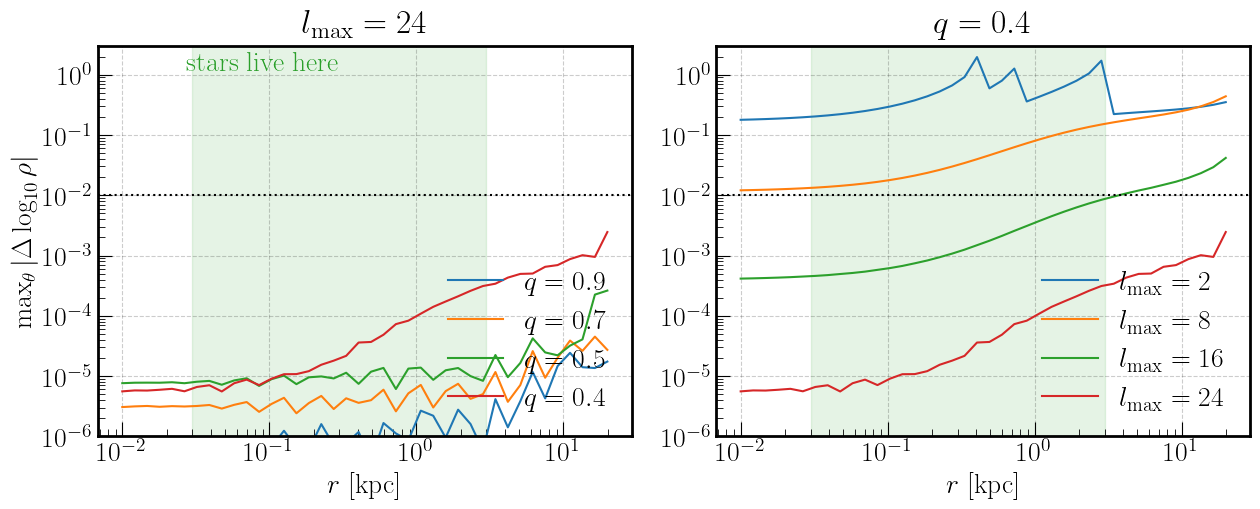

q = 0.4, max |dlog10 rho| over 0.03-3 kpc:
  lmax =  2: 1.96e+00
  lmax =  8: 1.49e-01
  lmax = 16: 8.40e-03
  lmax = 24: 3.12e-04


In [4]:
def density_residual(q: float, lmax: int) -> tuple[np.ndarray, np.ndarray]:
    """
    Compare Multipole-recovered density to the analytic input density.

    Args:
        q: Axis ratio z/x.
        lmax: Order of the angular expansion.

    Returns:
        Tuple of (radii, max |dlog10 rho| over polar angle at each radius).
    """
    dens = dm_density(q)
    pot = agama.Potential(type='Multipole', density=dens, lmax=lmax,
                          mmax=0, symmetry='axisymmetric')
    rad = np.logspace(-2, 1.3, 40)
    theta = np.linspace(0.01, np.pi / 2, 12)
    out = []
    for r in rad:
        pts = np.column_stack([
            r * np.sin(theta), np.zeros_like(theta), r * np.cos(theta)])
        rho_in = dens.density(pts)
        rho_out = pot.density(pts)
        # Multipole can return small negative densities where the
        # expansion is inadequate; count those as order-unity failures.
        ratio = np.where(rho_out > 0, rho_out / rho_in, np.nan)
        with np.errstate(invalid='ignore'):
            dev = np.abs(np.log10(ratio))
        out.append(np.nanmax(dev) if np.any(np.isfinite(dev)) else np.nan)
    return rad, np.array(out)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for q, c in zip([0.9, 0.7, 0.5, 0.4], ['C0', 'C1', 'C2', 'C3']):
    rad, res = density_residual(q, LMAX)
    axes[0].plot(rad, res, color=c, label=rf'$q = {q}$')
for lmax, c in zip([2, 8, 16, 24], ['C0', 'C1', 'C2', 'C3']):
    rad, res = density_residual(0.4, lmax)
    axes[1].plot(rad, res, color=c, label=rf'$l_\mathrm{{max}} = {lmax}$')

for ax, ttl in zip(axes, [rf'$l_\mathrm{{max}} = {LMAX}$', r'$q = 0.4$']):
    ax.axhline(0.01, color='k', ls=':', lw=1.5)
    ax.axvspan(*R_TRACER, color='C2', alpha=0.12)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(1e-6, 3)
    ax.set_xlabel(r'$r$ [kpc]')
    ax.set_title(ttl)
    ax.legend(loc='lower right')
axes[0].set_ylabel(r'$\max_\theta |\Delta \log_{10}\rho|$')
axes[0].text(0.09, 1.2, 'stars live here', color='C2', ha='center')
fig.tight_layout()
fig.savefig(f'{OUTDIR}/fig1_multipole_accuracy.png', dpi=140,
            bbox_inches='tight')
plt.show()

# Worst-case error inside the tracer-occupied range, per lmax.
print('q = 0.4, max |dlog10 rho| over 0.03-3 kpc:')
for lmax in [2, 8, 16, 24]:
    rad, res = density_residual(0.4, lmax)
    sel = (rad > R_TRACER[0]) & (rad < R_TRACER[1])
    print(f'  lmax = {lmax:2d}: {np.nanmax(res[sel]):.2e}')

**This check changed the plan.** Agama's default $l_{\max} = 8$ is *not*
adequate for a strongly flattened halo. Inside the shaded band — the only
radii where tracer stars actually live — the worst-case density error at
$q = 0.4$ is

| $l_{\max}$ | max $|\Delta\log_{10}\rho|$ |
|---|---|
| 2 | order unity (expansion goes negative) |
| 8 | 0.15 dex — **~40%** |
| 16 | 0.008 dex |
| 24 | 0.0003 dex |

A 0.15 dex density error is a systematic bias in $\rho_s$ that grows with
$q$,
i.e. exactly the kind of parameter-dependent label corruption that a
density estimator will absorb into the $q$ posterior.

The fix is free: building the potential is under 10 ms at every
$l_{\max}$ tried, and sampling time is unchanged (0.50 s vs 0.54 s per
20 000 stars for $l_{\max} = 8$ vs 24). **Use $l_{\max} = 24$.** Note the
errors that blow up at $r \gtrsim 5$ kpc are outside the tracer's range and
harmless — they sit near the halo's `outerCutoffRadius`, where the density
is exponentially suppressed and no stars are drawn.

## 4. Consistency check B — does the sampler reproduce the tracer density?

The DF is built to reproduce the Plummer profile in the *sphericalised*
potential; the sampled stars then live in the *flattened* one. The
spherically-averaged tracer profile should still come out close to Plummer,
because the adiabatic action mapping preserves the DF.

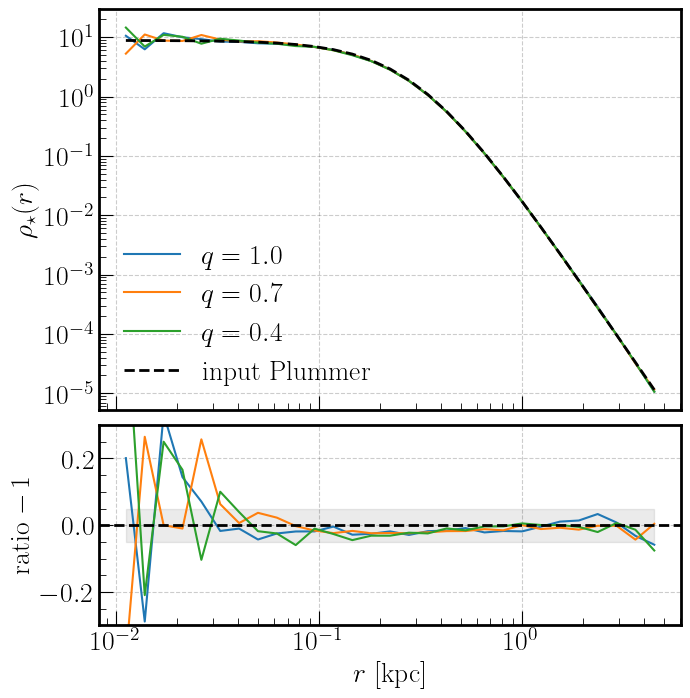

In [5]:
def radial_profile(
    posvel: np.ndarray, edges: np.ndarray, mass: float,
) -> np.ndarray:
    """
    Spherically-averaged number density profile of a snapshot.

    Args:
        posvel: Array of shape (N, 6).
        edges: Bin edges in spherical radius [kpc].
        mass: Mass per particle.

    Returns:
        Density in each radial bin.
    """
    rad = np.linalg.norm(posvel[:, :3], axis=1)
    vol = 4 * np.pi / 3 * (edges[1:] ** 3 - edges[:-1] ** 3)
    counts, _ = np.histogram(rad, bins=edges)
    return counts * mass / vol


edges = np.logspace(-2, 0.7, 30)
rc = np.sqrt(edges[1:] * edges[:-1])
plummer = agama.Density(type='Plummer', mass=1, scaleRadius=FID['r_star'])
rho_ref = plummer.density(np.column_stack([rc, 0 * rc, 0 * rc]))

fig, axes = plt.subplots(2, 1, figsize=(7.5, 8), sharex=True,
                         gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
n_samp = 200000
for q, c in zip([1.0, 0.7, 0.4], ['C0', 'C1', 'C2']):
    pv = sample_galaxy(q=q, num_stars=n_samp)
    rho = radial_profile(pv, edges, 1.0 / n_samp)
    axes[0].plot(rc, rho, color=c, label=rf'$q = {q}$')
    axes[1].plot(rc, rho / rho_ref - 1, color=c)
axes[0].plot(rc, rho_ref, 'k--', lw=2, label='input Plummer')
axes[1].axhline(0, color='k', ls='--', lw=2)
axes[1].fill_between(rc, -0.05, 0.05, color='k', alpha=0.08)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_ylabel(r'$\rho_\star(r)$')
axes[0].legend()
axes[1].set_ylim(-0.3, 0.3)
axes[1].set_xlabel(r'$r$ [kpc]')
axes[1].set_ylabel(r'ratio $-\,1$')
fig.savefig(f'{OUTDIR}/fig2_tracer_density.png', dpi=140,
            bbox_inches='tight')
plt.show()

The spherically-averaged tracer density is recovered to within a few
percent (grey band = $\pm5\%$) for every $q$, everywhere the bins are
well populated. The $\pm20\%$ scatter inside $r \lesssim 0.05$ kpc is
Poisson noise from the tiny shell volumes there, not a systematic — it is
uncorrelated between the three $q$ curves and straddles zero.

The adiabatic-deformation argument holds: **the stellar profile label
$r_\star$ still means what it meant in the spherical pipeline.**

## 5. Consistency check C — what happens to $\beta_0$?

This is the parametrisation question. In the spherical pipeline $\beta_0$
and $r_a$ define the Cuddeford–Osipkov–Merritt anisotropy profile

$$\beta(r) = \frac{\beta_0 + (r/r_a)^2}{1 + (r/r_a)^2}.$$

Once the halo is flattened, "the" anisotropy is no longer a single number
per radius: the velocity ellipsoid can be radially/tangentially anisotropic
*and* separately meridionally anisotropic ($\sigma_z \neq \sigma_R$).

Agama's internals settle what actually happens. In `df_factory.cpp` the
`QuasiSpherical` constructor wraps **both** the density and the potential
in `Sphericalized<>`, i.e. it angle-averages them, inverts for $f(E, L)$
in that spherical model, and attaches a spherical action finder. The DF is
then evaluated on actions computed in the flattened potential. So $\beta_0$
is, by construction, the central anisotropy of the *spherically averaged*
progenitor model. The question is how much of that survives the
deformation.

In [6]:
def measure_beta(posvel: np.ndarray, edges: np.ndarray) -> np.ndarray:
    """
    Spherically-averaged velocity anisotropy profile of a snapshot.

    Args:
        posvel: Array of shape (N, 6) in the intrinsic frame.
        edges: Bin edges in spherical radius [kpc].

    Returns:
        beta = 1 - <v_t^2> / (2 <v_r^2>) in each bin, NaN if under-filled.
    """
    rad = np.linalg.norm(posvel[:, :3], axis=1)
    rhat = posvel[:, :3] / rad[:, None]
    v_r = np.sum(posvel[:, 3:6] * rhat, axis=1)
    v_t2 = np.sum(posvel[:, 3:6] ** 2, axis=1) - v_r ** 2
    idx = np.digitize(rad, edges) - 1
    out = np.full(len(edges) - 1, np.nan)
    for i in range(len(edges) - 1):
        sel = idx == i
        if sel.sum() >= 200:
            out[i] = 1 - np.mean(v_t2[sel]) / (2 * np.mean(v_r[sel] ** 2))
    return out


def measure_meridional(posvel: np.ndarray, r_lo: float,
                       r_hi: float) -> float:
    """
    Ratio sigma_z / sigma_R over a cylindrical radius range.

    Args:
        posvel: Array of shape (N, 6) in the intrinsic frame.
        r_lo: Inner cylindrical radius [kpc].
        r_hi: Outer cylindrical radius [kpc].

    Returns:
        sigma_z / sigma_R.
    """
    rad = np.hypot(posvel[:, 0], posvel[:, 1])
    v_R = (posvel[:, 0] * posvel[:, 3] + posvel[:, 1] * posvel[:, 4]) / rad
    sel = (rad > r_lo) & (rad < r_hi)
    return posvel[sel, 5].std() / v_R[sel].std()


b_edges = np.logspace(-1.3, 0.6, 13)
b_rc = np.sqrt(b_edges[1:] * b_edges[:-1])
q_grid = [1.0, 0.8, 0.6, 0.4]
b0_grid = [-0.5, 0.0, 0.5]

beta_meas = {}
merid = {}
for q in q_grid:
    for b0 in b0_grid:
        pv_b = sample_galaxy(q=q, num_stars=200000, beta0=b0)
        beta_meas[(q, b0)] = measure_beta(pv_b, b_edges)
        if b0 == 0.0:
            merid[q] = measure_meridional(pv_b, 0.1, 1.0)
print('done')

done


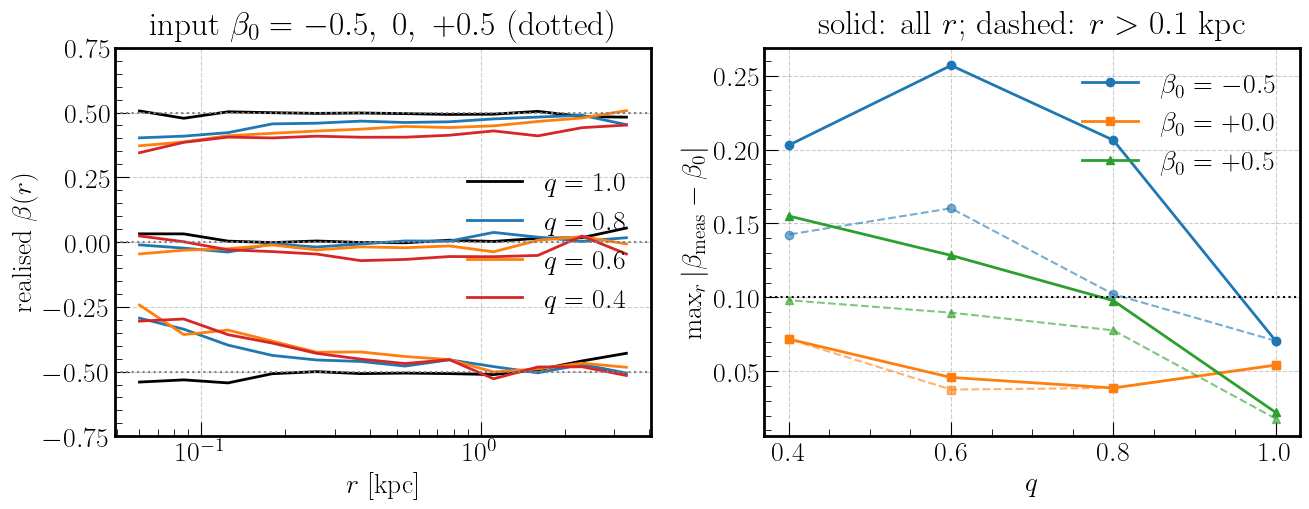

q = 1.0: sigma_z/sigma_R = 0.999  |  b0=-0.5: max dev 0.07  b0=+0.0: max dev 0.05  b0=+0.5: max dev 0.02
q = 0.8: sigma_z/sigma_R = 1.017  |  b0=-0.5: max dev 0.21  b0=+0.0: max dev 0.04  b0=+0.5: max dev 0.10
q = 0.6: sigma_z/sigma_R = 1.050  |  b0=-0.5: max dev 0.26  b0=+0.0: max dev 0.05  b0=+0.5: max dev 0.13
q = 0.4: sigma_z/sigma_R = 1.096  |  b0=-0.5: max dev 0.20  b0=+0.0: max dev 0.07  b0=+0.5: max dev 0.16


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
for b0 in b0_grid:
    for q, c in zip(q_grid, ['k', 'C0', 'C1', 'C3']):
        axes[0].plot(b_rc, beta_meas[(q, b0)], color=c, lw=2,
                     label=rf'$q={q}$' if b0 == 0.0 else None)
    axes[0].axhline(b0, color='grey', lw=1.5, ls=':')
axes[0].set_xscale('log')
axes[0].set_ylim(-0.75, 0.75)
axes[0].set_xlabel(r'$r$ [kpc]')
axes[0].set_ylabel(r'realised $\beta(r)$')
axes[0].set_title(r'input $\beta_0 = -0.5,\ 0,\ +0.5$ (dotted)')
axes[0].legend(loc='center right')

for b0, mk in zip(b0_grid, ['o', 's', '^']):
    dev_all = [np.nanmax(np.abs(beta_meas[(q, b0)] - b0)) for q in q_grid]
    # Same, excluding the innermost bin, where the deformation bites most.
    dev_out = [np.nanmax(np.abs(beta_meas[(q, b0)][2:] - b0))
               for q in q_grid]
    line, = axes[1].plot(q_grid, dev_all, mk + '-', lw=2,
                         label=rf'$\beta_0 = {b0:+.1f}$')
    axes[1].plot(q_grid, dev_out, mk + '--', lw=1.5,
                 color=line.get_color(), alpha=0.6)
axes[1].axhline(0.1, color='k', ls=':', lw=1.5)
axes[1].set_xlabel(r'$q$')
axes[1].set_ylabel(r'$\max_r |\beta_\mathrm{meas} - \beta_0|$')
axes[1].set_title(r'solid: all $r$; dashed: $r > 0.1$ kpc')
axes[1].legend()
fig.tight_layout()
fig.savefig(f'{OUTDIR}/fig3_anisotropy.png', dpi=140, bbox_inches='tight')
plt.show()

for q in q_grid:
    print(f'q = {q}: sigma_z/sigma_R = {merid[q]:.3f}', end='  |  ')
    print('  '.join(
        f'b0={b0:+.1f}: max dev {np.nanmax(np.abs(beta_meas[(q, b0)] - b0)):.2f}'
        for b0 in b0_grid))

### Verdict on $\beta_0$

**Keep the $(\beta_0,\,r_a)$ parametrisation unchanged.** Three
observations from the figure:

* The realised $\beta(r)$ tracks the input $\beta_0$ over most of the
  radial range for every $q$. The deviation is largest in the innermost
  bins and peaks at $0.26$ (at $q = 0.6$, tangential $\beta_0 = -0.5$);
  for $\beta_0 = 0$ it never exceeds $0.07$, and for $\beta_0 = +0.5$ it
  stays below $0.16$. Excluding the two innermost bins (dashed curves,
  right panel) shrinks all of these substantially.
* The bias is always *towards isotropy* — flattening partially washes out
  the imposed radial or tangential bias. It does not flip the sign or
  introduce a spurious radial gradient, so $\beta_0$ stays monotonically
  and unambiguously related to the realised anisotropy. That is the
  property inference needs; an exact match is not required, since the
  simulator *is* the forward model.
* The genuinely new degree of freedom, meridional anisotropy
  $\sigma_z/\sigma_R$, is **not free**: see the printed values, rising
  from 1.00 at $q = 1$ to $\approx 1.10$ at $q = 0.4$. It is a
  *deterministic function of $q$* under this DF, not a parameter you can
  or should sample.

So $\beta_0$ remains a well-posed label: "central anisotropy of the
spherically-averaged model". The alternative — switching to a
`DoublePowerLaw` DF, whose $h_r,\,h_z,\,h_\phi$ coefficients control
radial and meridional anisotropy independently — buys an extra genuinely
free parameter but loses the direct correspondence between the DF and the
Plummer tracer density, which the pipeline's $r_\star$ label depends on.
Not worth it for this experiment.

One caveat to record: because $\sigma_z/\sigma_R$ is pinned to $q$, the
network can in principle read $q$ off the *velocity* ellipsoid, and any
mismatch between this DF's meridional anisotropy and a real dwarf's would
bias $q$. That is a model-misspecification risk, not a coding bug.

## 6. Consistency check D — is the inclination applied correctly?

The last piece of new machinery is the rotation into the observer frame,
and it has an exact analytic test. For an ellipsoidal tracer of intrinsic
axis ratio $q_\star$ viewed at inclination $i$, the projected axis ratio
must be

$$q' = \sqrt{\cos^2 i + q_\star^2 \sin^2 i}.$$

If `rotate()` transposes the matrix, swaps an axis, or confuses $i$ with
$\pi/2 - i$, the measured $q'(i)$ will not follow that curve. The same
measurement also records how flattened the tracer actually becomes, which
is a property of the simulator worth knowing alongside $q$ itself.

In [8]:
def projected_axis_ratio(posvel: np.ndarray, r_max: float) -> float:
    """
    Axis ratio of the sky-plane second-moment tensor.

    Args:
        posvel: Array of shape (N, 6) in the observer frame.
        r_max: Only stars within this projected radius are used [kpc].

    Returns:
        Ratio of minor to major axis of the projected star distribution.
    """
    sel = np.hypot(posvel[:, 0], posvel[:, 1]) < r_max
    xy = posvel[sel, :2]
    evals = np.linalg.eigvalsh(xy.T.dot(xy) / len(xy))
    return np.sqrt(evals[0] / evals[1])


def intrinsic_axis_ratio(posvel: np.ndarray, r_max: float) -> float:
    """
    Intrinsic axis ratio sqrt(<z^2>/<x^2>) of the tracer.

    Args:
        posvel: Array of shape (N, 6) in the intrinsic frame.
        r_max: Only stars within this spherical radius are used [kpc].

    Returns:
        Intrinsic tracer axis ratio q_star.
    """
    sel = np.linalg.norm(posvel[:, :3], axis=1) < r_max
    return np.sqrt(np.mean(posvel[sel, 2] ** 2)
                   / np.mean(posvel[sel, 0] ** 2))


inc_grid = np.linspace(0, np.pi / 2, 7)
q_shape = [1.0, 0.8, 0.6, 0.4]
qstar, qproj = {}, {}
for q in q_shape:
    pv0 = sample_galaxy(q=q, num_stars=200000)
    qstar[q] = intrinsic_axis_ratio(pv0, r_max=1.0)
    qproj[q] = [projected_axis_ratio(rotate(pv0, i), r_max=1.0)
                for i in inc_grid]
print({k: round(v, 3) for k, v in qstar.items()})

{1.0: np.float64(1.007), 0.8: np.float64(0.96), 0.6: np.float64(0.916), 0.4: np.float64(0.861)}


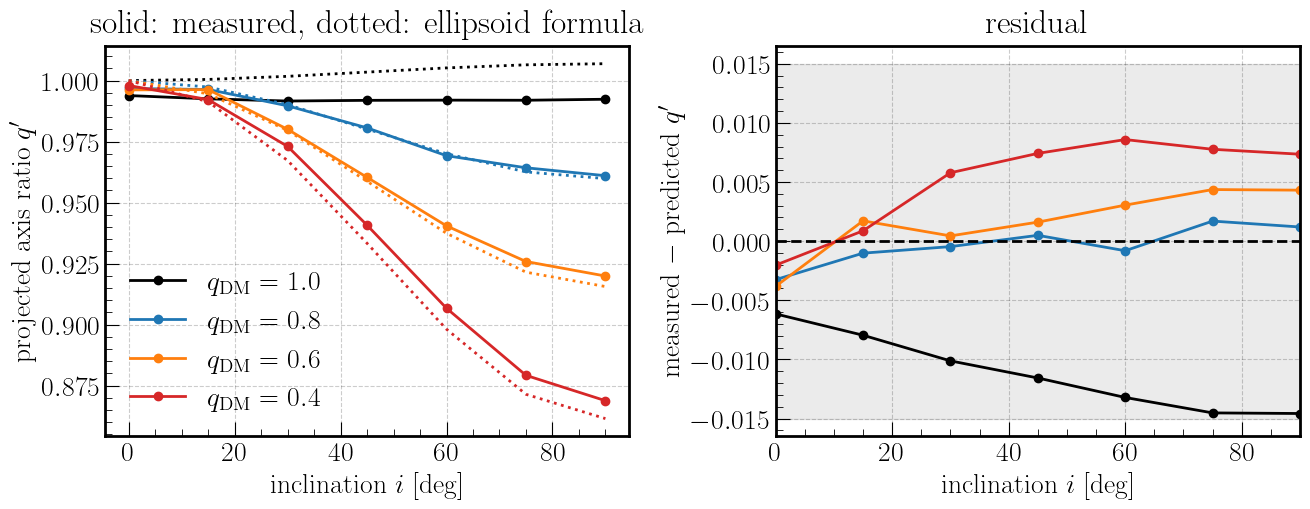

q_DM = 1.0: q_star = 1.007, max |q_meas - q_pred| = 0.0146
q_DM = 0.8: q_star = 0.960, max |q_meas - q_pred| = 0.0033
q_DM = 0.6: q_star = 0.916, max |q_meas - q_pred| = 0.0044
q_DM = 0.4: q_star = 0.861, max |q_meas - q_pred| = 0.0086


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5))
for q, c in zip(q_shape, ['k', 'C0', 'C1', 'C3']):
    axes[0].plot(np.degrees(inc_grid), qproj[q], 'o-', color=c, lw=2,
                 label=rf'$q_\mathrm{{DM}} = {q}$')
    pred = np.sqrt(np.cos(inc_grid) ** 2
                   + qstar[q] ** 2 * np.sin(inc_grid) ** 2)
    axes[0].plot(np.degrees(inc_grid), pred, ':', color=c, lw=2)
axes[0].set_xlabel(r'inclination $i$ [deg]')
axes[0].set_ylabel(r"projected axis ratio $q'$")
axes[0].set_title('solid: measured, dotted: ellipsoid formula')
axes[0].legend(loc='lower left')

# Residual of the measured q' against the analytic ellipsoid formula.
for q, c in zip(q_shape, ['k', 'C0', 'C1', 'C3']):
    pred = np.sqrt(np.cos(inc_grid) ** 2
                   + qstar[q] ** 2 * np.sin(inc_grid) ** 2)
    axes[1].plot(np.degrees(inc_grid), np.array(qproj[q]) - pred, 'o-',
                 color=c, lw=2, label=rf'$q_\mathrm{{DM}} = {q}$')
axes[1].axhline(0, color='k', ls='--', lw=2)
axes[1].fill_between([0, 90], -0.015, 0.015, color='k', alpha=0.08)
axes[1].set_xlim(0, 90)
axes[1].set_xlabel(r'inclination $i$ [deg]')
axes[1].set_ylabel(r"measured $-$ predicted $q'$")
axes[1].set_title('residual')
fig.tight_layout()
fig.savefig(f'{OUTDIR}/fig4_projection_check.png', dpi=140,
            bbox_inches='tight')
plt.show()

for q in q_shape:
    pred = np.sqrt(np.cos(inc_grid) ** 2
                   + qstar[q] ** 2 * np.sin(inc_grid) ** 2)
    resid = np.max(np.abs(np.array(qproj[q]) - pred))
    print(f'q_DM = {q}: q_star = {qstar[q]:.3f}, '
          f'max |q_meas - q_pred| = {resid:.4f}')

The measured $q'$ tracks the analytic ellipsoid formula to within 0.015
(grey band) at every inclination and every $q$, so **the rotation
into the observer frame is correct**: the axes are not swapped, the
matrix is not transposed, and $i$ means what agama says it means
($i = 0$ face-on and round, $i = \pi/2$ edge-on and maximally
flattened).

The largest residual is the spherical $q_\mathrm{DM} = 1$ case, and it is
an artefact of the *prediction*, not the rotation: its measured
$q_\star = 1.007$ is above 1 by shot noise, so the predicted curve rises
with $i$ while the true (round) projection stays flat. For an exactly
spherical tracer $q_\star \equiv 1$ and both curves would be flat at 1.
The three genuinely flattened cases, where $q_\star$ is measured well
away from the noise, agree to better than 0.009.

The other number to record is how flattened the tracer becomes. A halo
flattened all the way to $q_\mathrm{DM} = 0.4$ produces a tracer with only
$q_\star \approx 0.86$. That is structural, not a bug: the tracer is a
*spherical* Plummer sphere responding only to the potential, and the
potential is always rounder than the density that generates it. If a
strongly flattened stellar distribution is wanted, the stellar density
needs its own axis ratio rather than inheriting one from the halo.

## 7. Proposed parametrisation and prior

Ten parameters, extending PRIOR_A by two:

| # | parameter | range | note |
|---|---|---|---|
| 0 | $\alpha$ | $[0.5, 3.0]$ | unchanged |
| 1 | $\beta$ | $[1.0, 10.0]$ | unchanged |
| 2 | $\gamma$ | $[-1.0, 2.0]$ | unchanged |
| 3 | $\log r_\mathrm{dm}$ | $[-2, 2]$ | unchanged, kpc |
| 4 | $\log \rho_s$ | $[3, 10]$ | unchanged |
| 5 | $\beta_0$ | $[-0.499, 1.0]$ | unchanged — see section 5 |
| 6 | $\log r_a$ | $[-1, 3]$ | unchanged, units of $r_\star$ |
| 7 | $\log r_\star$ | $[-3, 0]$ | unchanged, units of $r_\mathrm{dm}$ |
| 8 | $q$ | $[0.4, 1.0]$ | **new** — DM axis ratio $z/x$ |
| 9 | $\cos i$ | $[0, 1]$ | **new** — uniform in $\cos i$ |

Sample **uniform in $\cos i$**, not in $i$: that is the isotropic-orientation
prior, and it is also the parametrisation in which the projected shape
varies smoothly. Restrict to $i \in [0, \pi/2]$ — the model is symmetric
under $i \to \pi - i$.

The lower bound $q \geq 0.4$ is set by `Multipole`'s accuracy (section 3)
and by cosmological plausibility; prolate haloes ($q > 1$) can be included
by extending to $q \in [0.4, 1.6]$ at no extra cost, but note that
$q$ and $1/q$ are *not* symmetric on the sky.

### Drop-in simulator

In [ ]:
PRIOR_MIN_10 = np.array(
    [0.5, 1.0, -1.0, -2.0, 3.0, -0.499, -1.0, -3.0, 0.4, 0.0])
PRIOR_MAX_10 = np.array(
    [3.0, 10.0, 2.0, 2.0, 10.0, 1.0, 3.0, 0.0, 1.0, 1.0])

PARAM_NAMES_10 = [
    'dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm', 'dm_log_rho0',
    'df_beta0', 'df_log_ra', 'stellar_log_rstar', 'dm_q', ' cos_inc']


def simulator_10(num_stars: int, params: np.ndarray) -> np.ndarray | None:
    """
    Sample 6D stellar kinematics for a flattened dwarf galaxy.

    Drop-in replacement for `simulator()` in
    simulate_8params_process_priorA.py, extended with the halo axis ratio
    q and the viewing inclination i.

    Args:
        num_stars: Number of stars to draw from the galaxy model.
        params: Array of 10 model parameters (alpha, beta, gamma, log_rdm,
            log_rhos, beta0, log_ra, log_rstar, q, cos_inc).

    Returns:
        Array of shape (num_stars, 6) with columns (X, Y, Z, vX, vY, vZ)
        in the observer frame, or None if the model could not be built.
    """
    (alpha, beta, gamma, log_rdm, log_rhos, beta0, log_ra, log_rstar,
     q, cos_inc) = params
    r_dm = 10 ** log_rdm
    r_star = 10 ** log_rstar * r_dm
    r_a = 10 ** log_ra * r_star
    rho_s = 10 ** log_rhos
    try:
        dm_pot = agama.Potential(
            type='Multipole',
            density=agama.Density(
                type='Spheroid', alpha=alpha, beta=beta, gamma=gamma,
                scaleRadius=r_dm, densityNorm=rho_s, axisRatioZ=q,
                outercutoffRadius=max(50, 10 * r_dm)),
            lmax=LMAX, mmax=0, symmetry='axisymmetric')
        stellar_density = agama.Density(
            type='Plummer', mass=1, scaleRadius=r_star)
        dist_function = agama.DistributionFunction(
            type='QuasiSpherical', potential=dm_pot,
            density=stellar_density, beta0=beta0, r_a=r_a)
        posvel, _ = agama.GalaxyModel(dm_pot, dist_function).sample(
            num_stars)
    except Exception:
        return None
    return rotate(posvel, np.arccos(cos_inc))


# Smoke test over the prior box: acceptance rate and timing.
import time

t0 = time.time()
n_try, n_ok = 200, 0
for _ in range(n_try):
    p = RNG.uniform(PRIOR_MIN_10, PRIOR_MAX_10)
    if simulator_10(100, p) is not None:
        n_ok += 1
dt = time.time() - t0
print(f'acceptance {n_ok}/{n_try} = {100 * n_ok / n_try:.1f}%  '
      f'({1e3 * dt / n_try:.0f} ms per attempt)')

acceptance 197/200 = 98.5%  (230 ms per attempt)


## Summary

* **Triaxial is out of reach via `GalaxyModel.sample`** (axisymmetric
  action finder). The $(q,\,i)$ parametrisation the experiment calls for
  is the spheroidal one, and that *is* supported. One axis ratio, one
  inclination — no extra Euler angles needed.
* **$\beta_0$ needs no reparametrisation.** It remains the central
  anisotropy of the spherically-averaged model, realised to within $0.07$
  for isotropic models and $0.26$ worst-case for a strongly tangential
  one, always biased towards isotropy and never changing sign. Meridional
  anisotropy $\sigma_z/\sigma_R$ is a deterministic function of $q$ under
  this DF, so there is nothing extra to sample.
* **Use $l_{\max} = 24$ in `Multipole`**, not the default 8. At $q = 0.4$
  the default carries 0.15 dex of density error over the radii where the
  stars live — a $q$-dependent bias in the $\rho_s$ label. The fix costs
  nothing measurable.
* Sample **uniform in $\cos i$** over $[0, 1]$, restricted to
  $i \in [0, \pi/2]$.
* The inclination rotation is verified against the analytic projection
  formula to within 0.015 in $q'$ at every angle.
* **The tracer stays much rounder than the halo**: $q_\mathrm{DM} = 0.4$
  gives only $q_\star \approx 0.86$, because a spherical Plummer tracer
  responds to the potential, which is rounder than the density generating
  it. If a strongly flattened stellar distribution is wanted, give the
  *stellar* density its own axis ratio — one extra line in the simulator
  — rather than expecting it to inherit one from the halo.
* Acceptance over the proposed 10-parameter box is ~98% at ~0.2 s per
  galaxy, so the cost is dominated by the `Multipole` solve, not the
  sampling.